# 02 · Comparativa RNN simple vs LSTM vs GRU

Este notebook **no entrena nada**: carga los resultados guardados en `reports/results/` por el
pipeline (`tune` → `evaluate` → `timing` → `summarize`, ejecutado en la GPU) y los analiza.
Todas las métricas son fuera de muestra, en $/barril, sobre los mismos orígenes de previsión del
periodo de test (desde el 1-1-2022) para las tres redes y el modelo ingenuo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from oilcast.config import load_config
from oilcast.evaluation.report import comparison_table, stability_table, year_table
from oilcast.models.recurrent import ARCH_LABELS
from oilcast.paths import get_paths
from oilcast.training.tune import tuning_summary
from oilcast.utils import read_json

cfg = load_config()
paths = get_paths(cfg)
archs, horizons = cfg["architectures"], cfg["targets"]["horizons"]
comp = pd.read_csv(paths.results / "comparison.csv")
by_year = pd.read_csv(paths.results / "metrics_by_year.csv")
timing = pd.read_csv(paths.results / "timing.csv")
selection = read_json(paths.results / "selection.json")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

## 1. Diseño experimental

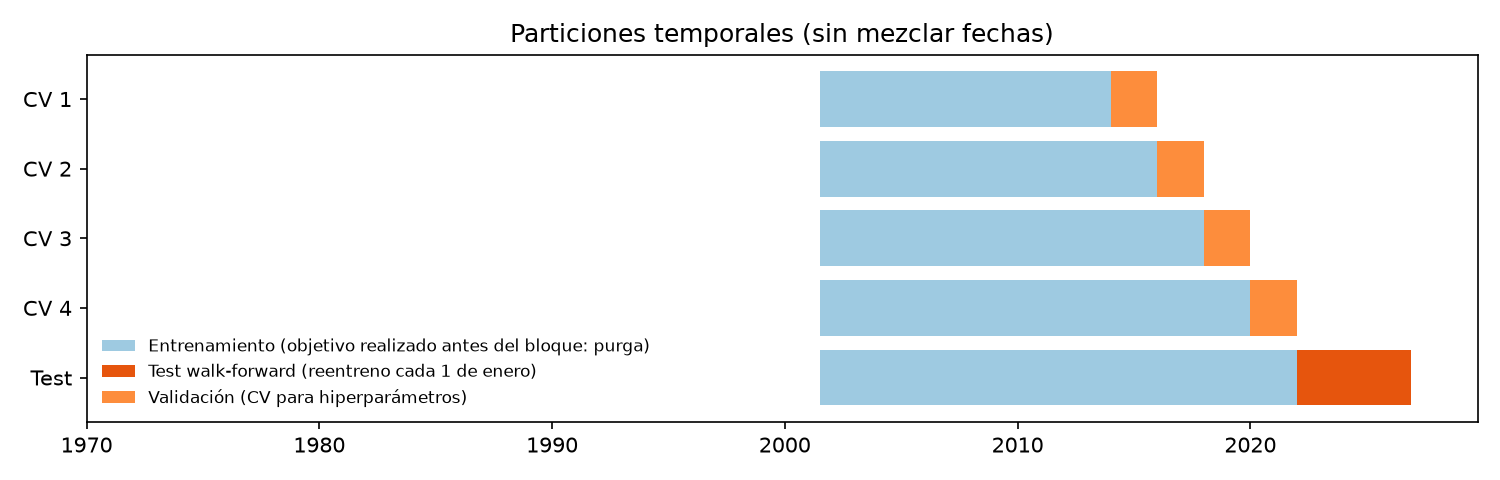

In [2]:
display(Image(paths.figures / "particiones.png"))

- **CV de hiperparámetros**: 4 bloques de validación de 2 años; para cada bloque se entrena solo
  con orígenes cuyo objetivo (precio a h días) ya se conoce antes de que empiece el bloque
  (*purga*). Optuna TPE, 80 trials por red y horizonte, misma semilla y mismo espacio
  (16-256 neuronas, 1-3 capas).
- **Sin deriva**: las redes aprenden desviaciones respecto a la media del entrenamiento, para que
  no proyecten al futuro la subida de 2001-2013.
- **Test**: reentreno cada 1 de enero (2022…2026) con todo lo realizado antes, hiperparámetros y
  nº de épocas fijados en la CV (sin *early stopping* sobre test), 5 semillas.
- **Recalibración del centro**: la mediana se encoge hacia el ingenuo con un factor en [0, 1]
  estimado con los errores ya conocidos en cada fecha.
- **Intervalos**: cuantiles 10-90 % de la red + calibración conformal con errores ya realizados
  antes de cada previsión.

Esta configuración es la adoptada tras dos rondas de experimentos (ver
`docs/registro-experimentos.md` y `docs/experimento-ronda2.md`); las variantes se resumen en
`reports/experiments/seleccion.csv`.

## 2. Hiperparámetros elegidos y pérdida de validación

In [3]:
tun = tuning_summary(paths, archs, horizons)
folds = {
    f"{a}_h{h}": read_json(paths.tuning_dir(a, h) / "best.json") for a in archs for h in horizons
}
tun.assign(
    pinball_por_fold=[
        np.round(folds[f"{r.arch}_h{r.horizon}"]["fold_losses"], 3).tolist()
        for r in tun.itertuples()
    ]
).round(4)

,arch,horizon,cv_pinball,final_epochs,n_trials,n_pruned,hidden_size,num_layers,dropout,lr,weight_decay,batch_size,pinball_por_fold
0,rnn,5,0.2464,25,80,31,64,1,0.4978,0.0006,0.0000,128,"[0.2, 0.221, 0.177, 0.387]"
1,rnn,63,0.2741,16,80,34,256,3,0.4332,0.0016,0.0026,64,"[0.286, 0.147, 0.219, 0.444]"
2,rnn,252,0.2519,9,80,43,256,1,0.3817,0.0017,0.0005,128,"[0.374, 0.12, 0.262, 0.252]"
3,lstm,5,0.2450,3,80,40,256,3,0.0859,0.0009,0.0005,128,"[0.195, 0.218, 0.18, 0.387]"
4,lstm,63,0.2813,14,80,24,128,3,0.4837,0.0011,0.0000,256,"[0.334, 0.137, 0.221, 0.434]"
5,lstm,252,0.2692,22,80,48,64,3,0.1095,0.0026,0.0033,128,"[0.454, 0.102, 0.254, 0.267]"
6,gru,5,0.2459,2,80,35,256,3,0.4684,0.0029,0.0097,128,"[0.199, 0.22, 0.179, 0.385]"
7,gru,63,0.2921,6,80,6,32,3,0.3473,0.0030,0.0000,256,"[0.362, 0.145, 0.221, 0.441]"
8,gru,252,0.2720,4,80,47,256,3,0.2460,0.0019,0.0076,64,"[0.508, 0.099, 0.271, 0.209]"


## 3. Tabla comparativa en test

In [4]:
display(Markdown(comparison_table(comp, horizons, archs)))

| Horizonte | Modelo | MAE ($) | RMSE ($) | R² | Mejora MAE vs ingenuo | Mejora RMSE vs ingenuo | p-valor DM | Acierto direccional | Cobertura IC80 | Anchura IC80 ($) | Winkler IC80 | Parámetros | Tiempo entren. (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Corto (5 d) | Ingenuo | 3.99 | 5.74 | 0.875 | — | — | — | — | 76.1 % | 10.61 | 19.93 | — | — |
| Corto (5 d) | RNN simple | 3.96 | 5.71 | 0.876 | +0.6 % | +0.5 % | 0.148 | 53.3 % | 78.1 % | 10.80 | 19.09 | 5959 | 0.8 |
| Corto (5 d) | LSTM | 3.99 | 5.74 | 0.875 | +0.0 % | +0.0 % | — | — | 74.7 % | 10.54 | 19.00 | 1339143 | 0.6 |
| Corto (5 d) | GRU | 3.99 | 5.74 | 0.875 | +0.0 % | +0.0 % | 0.445 | 50.7 % | 78.8 % | 11.41 | 19.16 | 1004807 | 0.4 |
| Medio (63 d) | Ingenuo | 11.94 | 17.44 | -0.207 | — | — | — | — | 84.1 % | 37.60 | 65.11 | — | — |
| Medio (63 d) | RNN simple | 12.32 | 16.90 | -0.133 | -3.1 % | +3.1 % | 0.509 | 56.6 % | 86.3 % | 44.47 | 63.31 | 331285 | 2.1 |
| Medio (63 d) | LSTM | 12.22 | 16.29 | -0.053 | -2.3 % | +6.6 % | 0.456 | 52.5 % | 87.4 % | 43.13 | 58.37 | 332181 | 1.5 |
| Medio (63 d) | GRU | 12.63 | 16.87 | -0.130 | -5.8 % | +3.2 % | 0.520 | 53.9 % | 86.4 % | 41.87 | 59.84 | 16277 | 0.2 |
| Largo (252 d) | Ingenuo | 16.50 | 22.53 | -1.466 | — | — | — | — | 93.4 % | 90.15 | 97.57 | — | — |
| Largo (252 d) | RNN simple | 15.00 | 17.84 | -0.548 | +9.1 % | +20.8 % | 0.413 | 57.0 % | 99.6 % | 88.38 | 88.55 | 68117 | 0.3 |
| Largo (252 d) | LSTM | 14.85 | 17.86 | -0.550 | +10.0 % | +20.7 % | 0.396 | 53.6 % | 99.6 % | 89.95 | 90.17 | 84181 | 1.1 |
| Largo (252 d) | GRU | 15.55 | 19.29 | -0.809 | +5.7 % | +14.4 % | 0.526 | 61.1 % | 98.9 % | 90.49 | 91.38 | 990229 | 1.1 |

*Mejora* = 1 − error del modelo / error del ingenuo. *p-valor DM*: Diebold-Mariano con varianza
HAC (h−1 retardos) sobre el error cuadrático. Cobertura y anchura del intervalo del 80 % tras la
calibración conformal (el ingenuo usa los cuantiles históricos de las variaciones a h días).

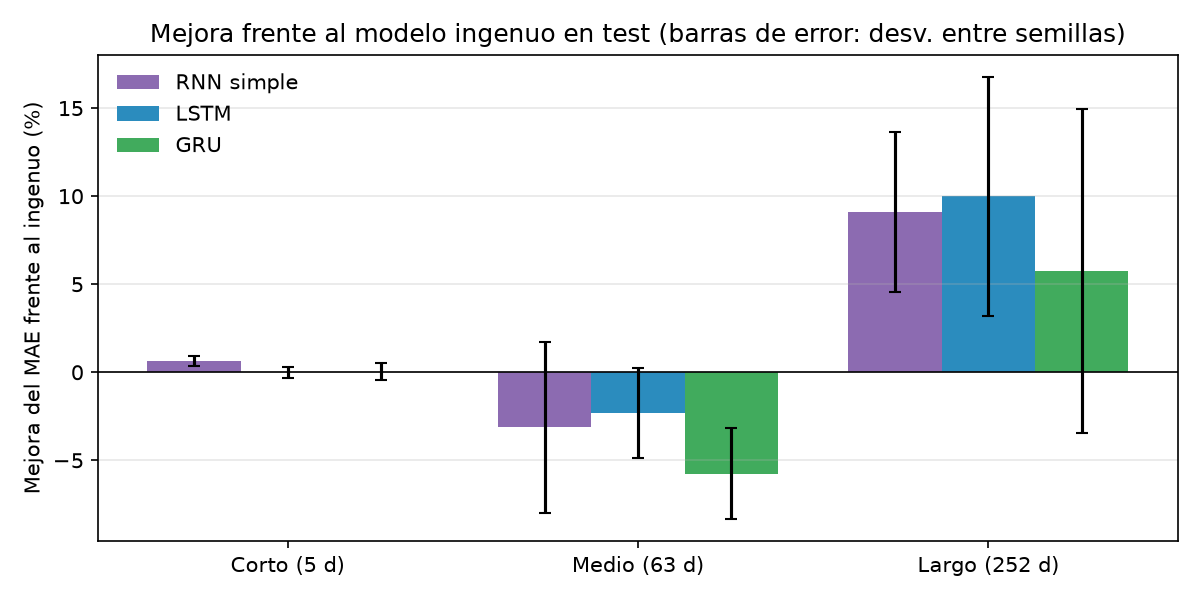

In [5]:
display(Image(paths.figures / "mejora_vs_ingenuo.png"))

## 4. Estabilidad entre semillas y calibración del intervalo

In [6]:
display(Markdown(stability_table(comp, horizons, archs)))

| Horizonte | Modelo | MAE ensemble | MAE por semilla (media ± desv.) | Mejora MAE por semilla (desv.) | Cobertura IC80 sin calibrar | MSE |
|---|---|---|---|---|---|---|
| Corto (5 d) | RNN simple | 3.96 | 3.94 ± 0.01 | 0.3 % | 73.4 % | 32.6 |
| Corto (5 d) | LSTM | 3.99 | 3.99 ± 0.01 | 0.3 % | 73.8 % | 32.9 |
| Corto (5 d) | GRU | 3.99 | 3.99 ± 0.02 | 0.5 % | 77.2 % | 32.9 |
| Medio (63 d) | RNN simple | 12.32 | 12.92 ± 0.58 | 4.8 % | 81.6 % | 285.5 |
| Medio (63 d) | LSTM | 12.22 | 12.26 ± 0.30 | 2.6 % | 80.3 % | 265.4 |
| Medio (63 d) | GRU | 12.63 | 13.02 ± 0.31 | 2.6 % | 81.7 % | 284.7 |
| Largo (252 d) | RNN simple | 15.00 | 15.19 ± 0.75 | 4.5 % | 98.0 % | 318.4 |
| Largo (252 d) | LSTM | 14.85 | 15.19 ± 1.12 | 6.8 % | 96.6 % | 319.0 |
| Largo (252 d) | GRU | 15.55 | 15.92 ± 1.52 | 9.2 % | 94.0 % | 372.3 |


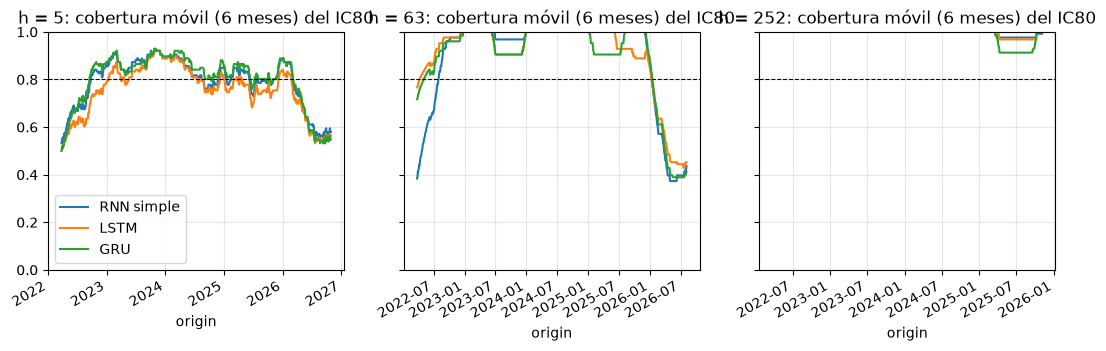

In [7]:
fig, axes = plt.subplots(1, len(horizons), figsize=(13, 3.5), sharey=True)
for ax, h in zip(axes, horizons, strict=True):
    for a in archs:
        e = pd.read_csv(
            paths.results / "predictions" / f"{a}_h{h}_ensemble.csv", parse_dates=["origin"]
        )
        t = e[e["phase"] == "test"].set_index("origin")
        inside = ((t["y"] >= t["lo80"]) & (t["y"] <= t["hi80"])).astype(float)
        inside.rolling(126, min_periods=60).mean().plot(ax=ax, label=ARCH_LABELS[a])
    ax.axhline(0.8, color="black", ls="--", lw=0.8)
    ax.set_title(f"h = {h}: cobertura móvil (6 meses) del IC80")
axes[0].legend()
axes[0].set_ylim(0, 1);

## 5. ¿Cuándo aporta valor? Resultados por año

In [8]:
display(Markdown(year_table(by_year, horizons, archs)))

| Horizonte | Modelo | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|---|
| Corto (5 d) | RNN simple | +1.0 % | +0.4 % | +1.5 % | +0.7 % | +0.0 % |
| Corto (5 d) | LSTM | +0.0 % | +0.0 % | +0.0 % | +0.0 % | +0.0 % |
| Corto (5 d) | GRU | +0.1 % | -0.0 % | +0.1 % | -0.0 % | +0.0 % |
| Corto (5 d) | MAE ingenuo ($) | 5.35 | 3.00 | 2.36 | 2.39 | 7.45 |
| Medio (63 d) | RNN simple | +12.0 % | +10.5 % | -65.1 % | -21.0 % | +4.6 % |
| Medio (63 d) | LSTM | +9.1 % | +4.1 % | -23.7 % | -41.9 % | +11.1 % |
| Medio (63 d) | GRU | +8.7 % | +6.9 % | -58.0 % | -33.9 % | +5.2 % |
| Medio (63 d) | MAE ingenuo ($) | 12.94 | 8.62 | 4.82 | 9.07 | 32.75 |
| Largo (252 d) | RNN simple | +45.1 % | -10.5 % | -122.2 % | +47.4 % | — |
| Largo (252 d) | LSTM | +42.4 % | -19.7 % | -96.9 % | +42.9 % | — |
| Largo (252 d) | GRU | +38.1 % | -31.4 % | -95.9 % | +38.6 % | — |
| Largo (252 d) | MAE ingenuo ($) | 19.32 | 7.61 | 11.43 | 29.64 | — |


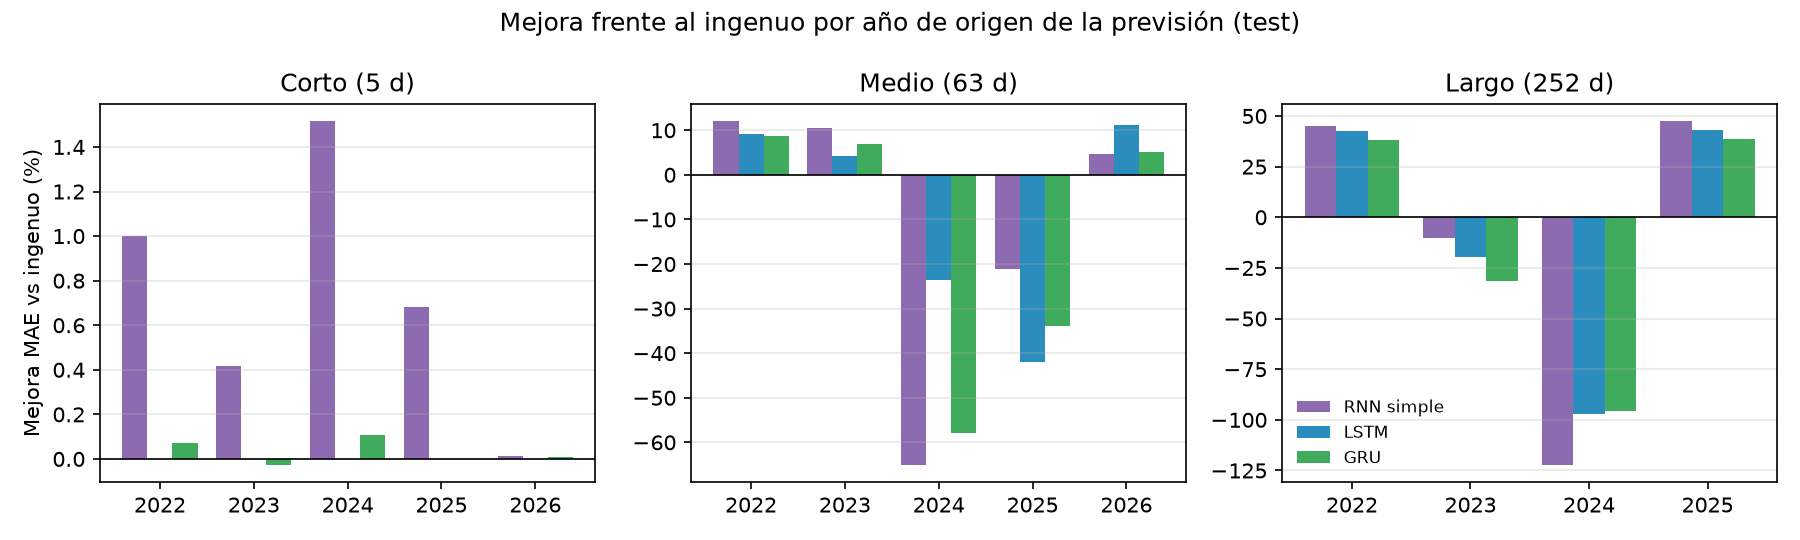

In [9]:
display(Image(paths.figures / "mejora_por_anio.png"))

## 6. ¿Qué predice realmente la red?

La mediana prevista por la red frente a la variación realizada. Una nube centrada cerca de 0 en
el eje vertical indica que la red ha aprendido que la mejor apuesta central es «casi sin cambio»
(y pone su valor en el rango); una pendiente clara indicaría capacidad direccional.

/Users/jorgesrab/development/marta/ia/oil-price-prediction Public/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/jorgesrab/development/marta/ia/oil-price-prediction Public/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


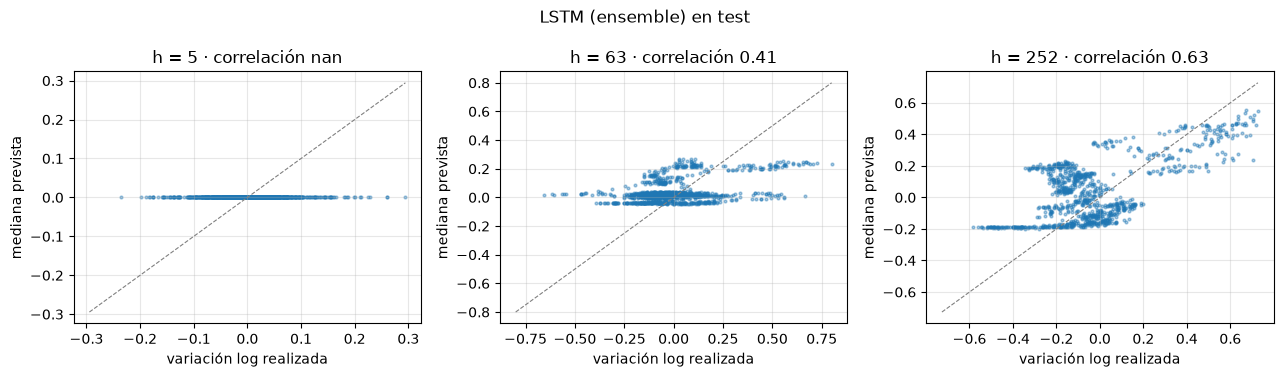

In [10]:
chosen = selection["chosen"]
fig, axes = plt.subplots(1, len(horizons), figsize=(13, 3.8))
for ax, h in zip(axes, horizons, strict=True):
    e = pd.read_csv(paths.results / "predictions" / f"{chosen}_h{h}_ensemble.csv")
    t = e[e["phase"] == "test"]
    ax.scatter(t["y"], t["q50"], s=4, alpha=0.4)
    lim = np.abs(t["y"]).max()
    ax.plot([-lim, lim], [-lim, lim], color="grey", lw=0.8, ls="--")
    rho = np.corrcoef(t["y"], t["q50"])[0, 1]
    ax.set_title(f"h = {h} · correlación {rho:.2f}")
    ax.set_xlabel("variación log realizada")
    ax.set_ylabel("mediana prevista")
fig.suptitle(f"{ARCH_LABELS[chosen]} (ensemble) en test")
fig.tight_layout();

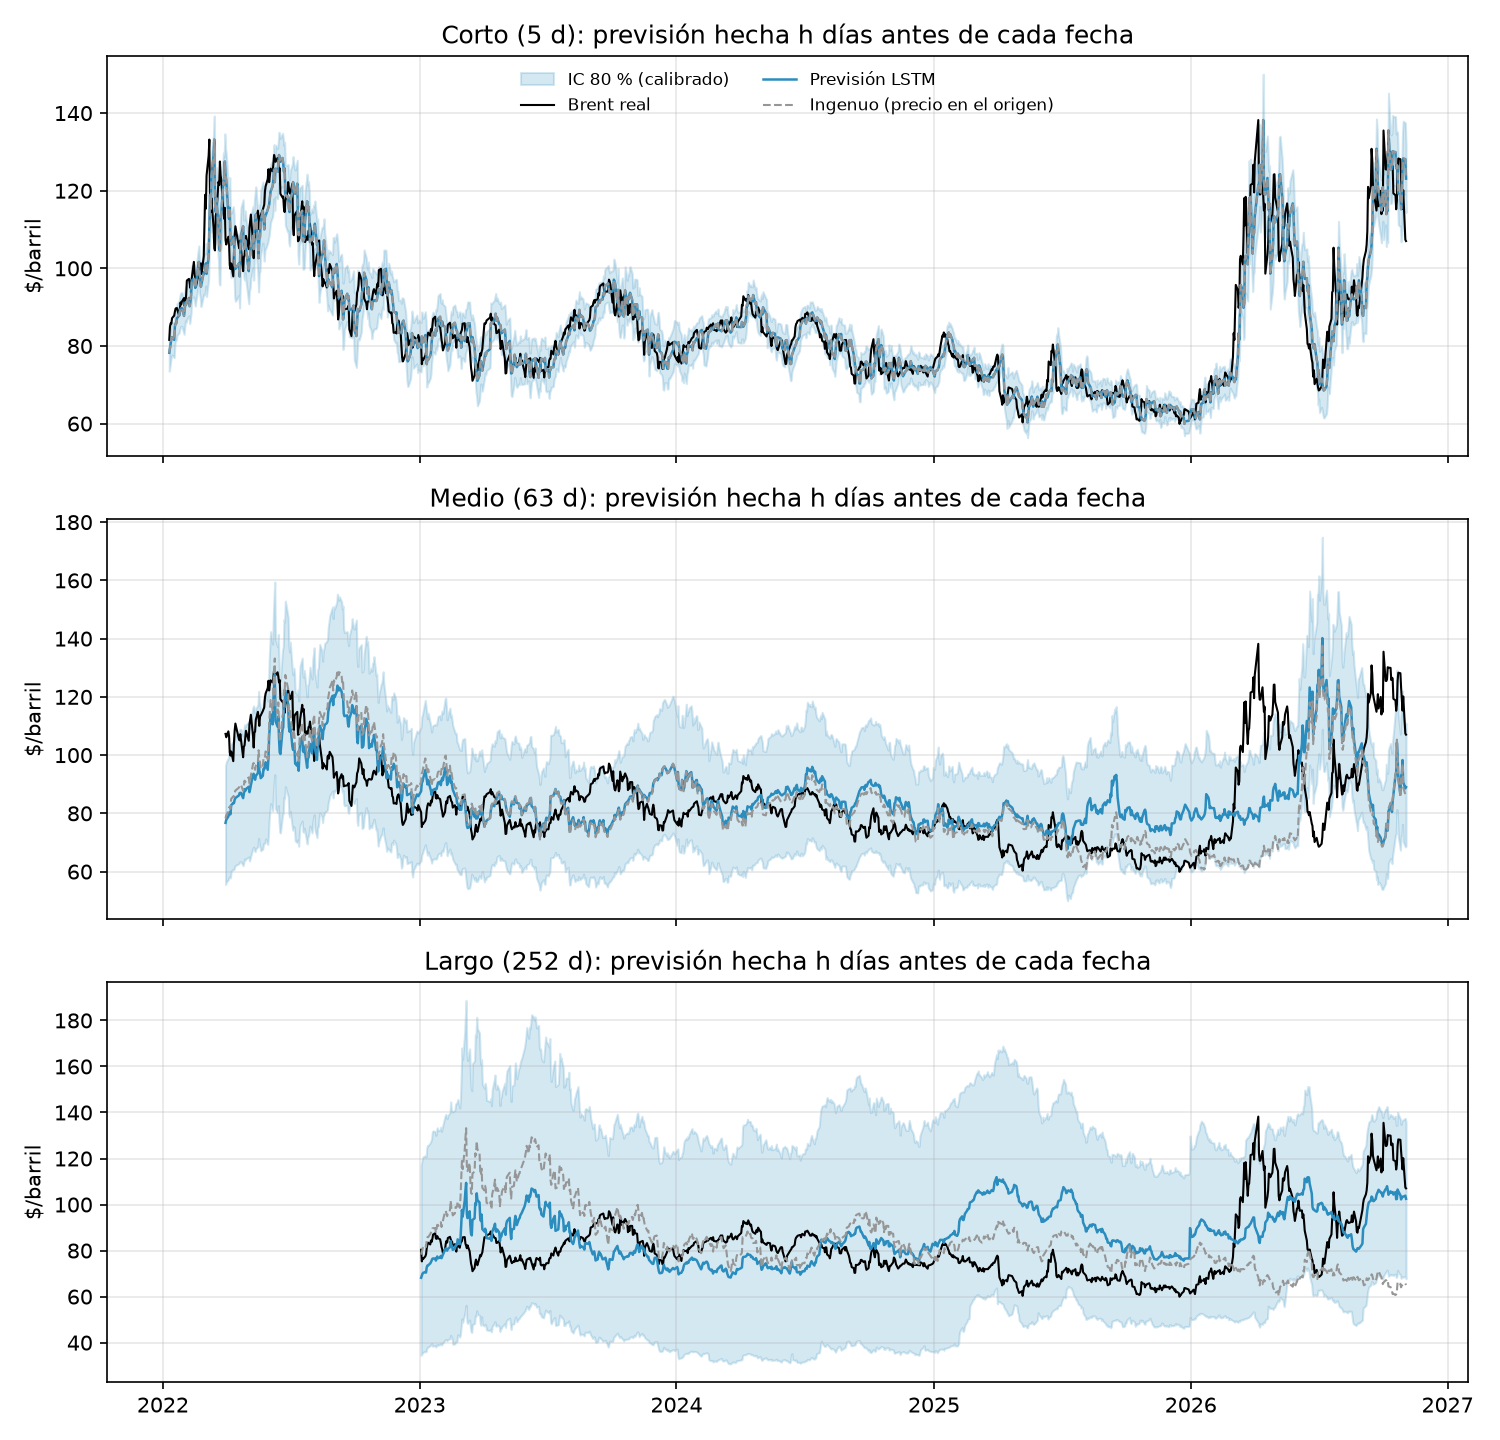

In [11]:
display(Image(paths.figures / "predicciones_test.png"))

## 7. Coste computacional

In [12]:
timing.pivot_table(
    index="arch", columns="horizon", values=["train_seconds", "n_params", "epochs"]
).round(1)

epochs               n_params                     train_seconds       \
horizon    5     63    252        5         63        252           5    63    
arch                                                                           
gru        2.0   6.0   4.0  1004807.0   16277.0  990229.0           0.4  0.2   
lstm       3.0  14.0  22.0  1339143.0  332181.0   84181.0           0.6  1.5   
rnn       25.0  16.0   9.0     5959.0  331285.0   68117.0           0.8  2.1   

              
horizon  252  
arch          
gru      1.1  
lstm     1.1  
rnn      0.3

## 8. Elección del modelo y conclusiones

In [13]:
print(selection["rule"])
pd.DataFrame(selection["scores"]).round(4)

regla fijada antes de la búsqueda de la ronda 4 (docs/experimento-ronda4.md): se elige la combinación de variante y red con mayor mejora media del MAE frente al ingenuo en los tres plazos, en orígenes de 2008 a 2021 con objetivo anterior a 2022, sin mirar el test. Ganó la LSTM con la relación oro/crudo a 63 y 252 sesiones (+5,3 % antes de 2022, +5,6 % en 2008-2013, años que no se usaron para elegir hiperparámetros).


,arch,mean_rel_mae,mean_rel_seed_std,mean_params,mean_coverage80
0,lstm,0.9744,0.0345,585168.3333,0.8724
1,rnn,0.9781,0.0332,135120.3333,0.8799
2,gru,0.9999,0.0424,670437.6667,0.8802


### Conclusiones

**Modelo elegido: LSTM (R4).** La red de la aplicación se fijó **antes de ver el test**, con la
regla de `docs/experimento-ronda4.md`: la combinación con mayor mejora media frente al ingenuo
en las predicciones anteriores a 2022 (+5,3 % en 2008-2021 y +5,6 % en 2008-2013, años que no
se usaron para elegir hiperparámetros). A 5 sesiones las redes reciben las 20 variables diarias.
A 63 y 252 solo reciben la relación oro/crudo (barriles por onza frente a su media de 3 años),
con un atajo lineal. El coste de entrenamiento es de segundos en GPU y no condiciona la
elección.

**Dónde aporta valor frente al ingenuo y dónde no** (LSTM):

- **Corto plazo (5 días)**: **igual que el ingenuo** (0,0 %). La recalibración del centro no
  encontró errores pasados que justificaran mover la previsión. El intervalo del 80 % es algo
  más informativo que el del ingenuo (Winkler 19,0 frente a 19,9).
- **Medio plazo (63 días)**: −2,3 % de MAE pero +6,6 % de RMSE: falla menos en los movimientos
  grandes, pero no en el error típico. **No significativa** (p = 0,46). El intervalo es mejor
  que el del ingenuo (Winkler 58,4 frente a 65,1).
- **Largo plazo (252 días)**: **+10,0 % de MAE y +20,7 % de RMSE**, no significativa (p = 0,40).
  Positiva en 2 de 4 años: casi toda la mejora viene de las previsiones de 2025, que acertaron
  la subida de 2026 por la guerra con Irán. Sin ellas, pierde un 11,6 % frente al ingenuo. En
  desarrollo ganó en 2008-2013 (+12,5 %) y en 2014-2021 (+13,3 %).

Es el resultado esperable para el crudo: con información de mercado pasada, el precio se
comporta casi como un paseo aleatorio. La única señal que resistió en varios periodos es lenta:
el crudo tiende a recuperarse cuando está muy barato medido en oro. La aplicación muestra
siempre el intervalo, dice en cada horizonte si el modelo mejoró o no al «precio no cambia» y
explica en qué se basa la previsión anual y qué la puede invalidar.

**Nota sobre la calibración**: el intervalo conformal usa todos los errores ya realizados
(ventana expansiva); con una ventana corta, a 252 días equivaldría a muy pocos años
independientes y daría intervalos degenerados. A 252 días el intervalo es prudente en exceso
(cubre el 99,6 % de los casos).